# Modelo generativo — Conditional VAE

En este notebook entrenamos un Conditional Variational Autoencoder (CVAE) para generar perfiles horarios de demanda electrica diaria en Argentina. El modelo recibe un vector de condiciones `C` con variables de calendario y clima, y genera un perfil de 24 horas consistente con esas condiciones.

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
from pathlib import Path
import sys
import numpy as np
import torch

project_root = Path.cwd()
if not (project_root / 'src').exists():
    project_root = project_root.parent
sys.path.append(str(project_root))

from src.data_quality import load_daily_datasets
from src.cvae import CVAE
from src.cvae_preprocessing import (
    remove_outlier_dates,
    build_condition_vector,
    build_profile_matrix,
    temporal_train_test_split,
    build_dataloaders,
)
from src.cvae_training import (
    train_cvae,
    plot_loss_curves,
    plot_reconstruction_vs_real,
    plot_generated_vs_real_by_condition,
)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cpu


## 1. Carga y preprocesamiento de datos

In [4]:
x_profiles, conditions = load_daily_datasets(
    x_path=project_root / 'x_perfiles_diarios.csv',
    c_path=project_root / 'c_condiciones_diarias.csv',
)

# Remover fechas outlier conocidas (apagon 2023-03-01)
x_profiles, conditions = remove_outlier_dates(x_profiles, conditions)

print(f'Dataset: {len(x_profiles)} dias')

Fechas removidas: 1 (['2023-03-01'])
Dataset: 1945 dias


### Vector condicional C

El vector condicional tiene 8 dimensiones:
- `tipo_dia`: one-hot de 4 categorias (habil, sabado, domingo, feriado)
- `mes`: codificacion ciclica con seno y coseno para evitar la discontinuidad entre diciembre y enero
- `grado_calor`: estandarizado
- `grado_frio`: estandarizado

In [5]:
C, condition_stats = build_condition_vector(conditions)
X, scaler_stats = build_profile_matrix(x_profiles)

print(f'X shape: {X.shape}  (dias x horas)')
print(f'C shape: {C.shape}  (dias x dimensiones condicion)')

C shape: (1945, 21)  — 21 dimensiones
X shape: (1945, 24)  — mean=15894.8 std=2862.8 MWh
X shape: (1945, 24)  (dias x horas)
C shape: (1945, 21)  (dias x dimensiones condicion)


### Split temporal train/test

Usamos un corte temporal para evitar data leakage: todo 2025 en adelante va a test y los años anteriores a train.

In [6]:
X_train, X_test, C_train, C_test, dates_train, dates_test = temporal_train_test_split(
    X, C, conditions['fecha'], test_year=2025
)

# Guardamos el subset de conditions para evaluacion por tipo de dia
conditions_test = conditions[conditions['fecha'].dt.year >= 2025].reset_index(drop=True)

train_loader, test_loader = build_dataloaders(
    X_train, C_train, X_test, C_test, batch_size=64
)

Train: 1460 dias (hasta 2024)
Test:  485 dias (2025 en adelante)


## 2. Definicion del modelo

Arquitectura del CVAE:
- **Encoder**: perfil (24) + condicion (8) → capa oculta (128) → mu y log_var (8)
- **Decoder**: latente (8) + condicion (8) → capa oculta (128) → perfil reconstruido (24)

El parametro `beta` controla el peso del termino KL en la loss. Con `beta=1` es un VAE estandar. Valores mayores organizan mejor el espacio latente pero pueden perjudicar la reconstruccion.

In [7]:
PROFILE_DIM = 24
CONDITION_DIM = C.shape[1]  # 8
HIDDEN_DIM = 128
LATENT_DIM = 8
BETA = 1.0

model = CVAE(
    profile_dim=PROFILE_DIM,
    condition_dim=CONDITION_DIM,
    hidden_dim=HIDDEN_DIM,
    latent_dim=LATENT_DIM,
)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Parametros entrenables: {n_params:,}')
print(model)

Parametros entrenables: 47,912
CVAE(
  (encoder): Encoder(
    (net): Sequential(
      (0): Linear(in_features=45, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=128, bias=True)
      (3): ReLU()
    )
    (mu_layer): Linear(in_features=128, out_features=8, bias=True)
    (log_var_layer): Linear(in_features=128, out_features=8, bias=True)
  )
  (decoder): Decoder(
    (net): Sequential(
      (0): Linear(in_features=29, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=128, bias=True)
      (3): ReLU()
      (4): Linear(in_features=128, out_features=24, bias=True)
    )
  )
)


## 3. Entrenamiento

In [8]:
history = train_cvae(
    model=model,
    train_loader=train_loader,
    test_loader=test_loader,
    n_epochs=200,
    learning_rate=1e-3,
    beta=BETA,
    device=device,
)

Epoch 020 | train loss: 0.0616 (recon 0.0610, kl 0.0006) | test loss: 0.0712 (recon 0.0705)
Epoch 040 | train loss: 0.0525 (recon 0.0522, kl 0.0004) | test loss: 0.0702 (recon 0.0698)
Epoch 060 | train loss: 0.0471 (recon 0.0468, kl 0.0003) | test loss: 0.0714 (recon 0.0712)
Epoch 080 | train loss: 0.0427 (recon 0.0427, kl 0.0001) | test loss: 0.0692 (recon 0.0691)
Epoch 100 | train loss: 0.0376 (recon 0.0375, kl 0.0001) | test loss: 0.0770 (recon 0.0770)
Epoch 120 | train loss: 0.0329 (recon 0.0328, kl 0.0000) | test loss: 0.0946 (recon 0.0946)
Epoch 140 | train loss: 0.0282 (recon 0.0282, kl 0.0000) | test loss: 0.0947 (recon 0.0947)
Epoch 160 | train loss: 0.0264 (recon 0.0264, kl 0.0000) | test loss: 0.0786 (recon 0.0786)
Epoch 180 | train loss: 0.0227 (recon 0.0227, kl 0.0000) | test loss: 0.1077 (recon 0.1077)
Epoch 200 | train loss: 0.0212 (recon 0.0212, kl 0.0000) | test loss: 0.1017 (recon 0.1017)

Mejor modelo restaurado (test recon: 0.0642)


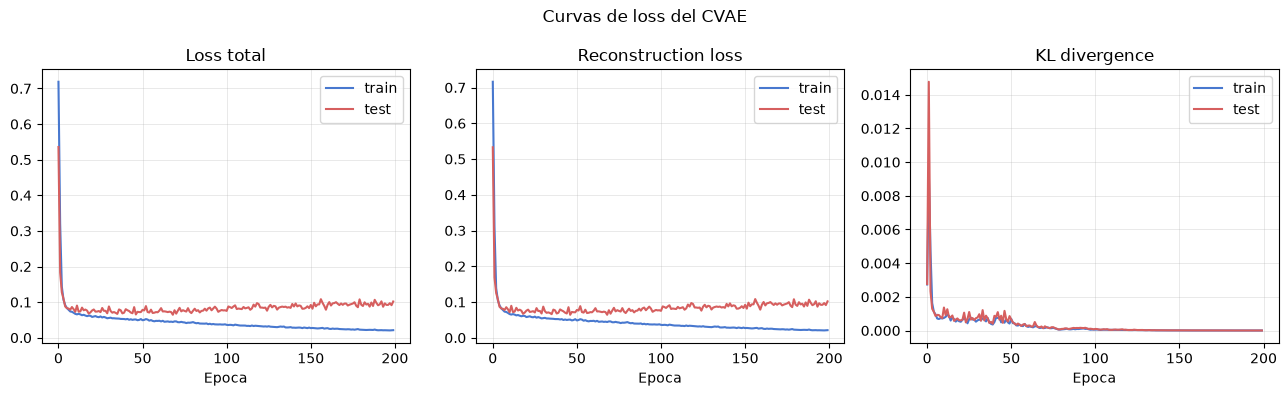

In [9]:
plot_loss_curves(history);

Completar con observaciones: si train y test convergen juntos (buen signo), si hay overfitting (test sube mientras train baja), si el KL colapsa a cero (el encoder ignora el input y el modelo degenera).

## 4. Evaluacion

### Reconstruccion de perfiles del test set

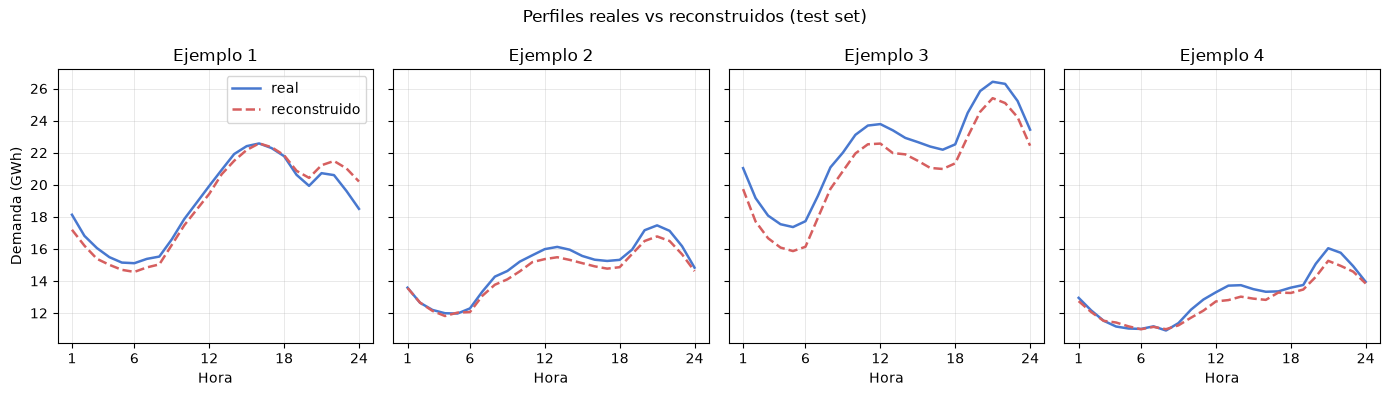

In [10]:
plot_reconstruction_vs_real(
    model=model,
    X_test=X_test,
    C_test=C_test,
    scaler_stats=scaler_stats,
    n_examples=4,
    device=device,
);

Completar con observaciones: si el modelo captura el valle de madrugada y el pico nocturno, si hay horas donde la reconstruccion es sistematicamente mala.

### Perfiles generados vs reales por tipo de dia

KeyError: 'tipo_dia'

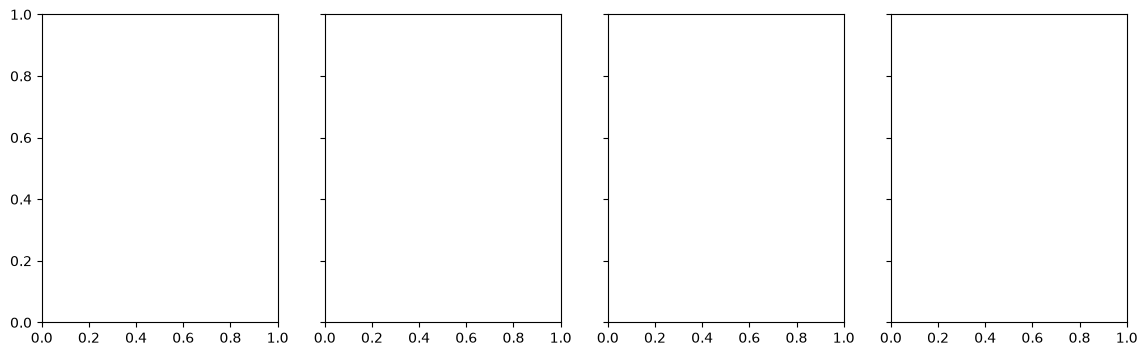

In [11]:
plot_generated_vs_real_by_condition(
    model=model,
    X_test=X_test,
    C_test=C_test,
    dates_test=dates_test,
    conditions_test=conditions_test,
    scaler_stats=scaler_stats,
    device=device,
);

Completar con observaciones: si el perfil medio generado para dias habiles tiene meseta diurna como los reales, si domingos y feriados generados muestran el unico pico nocturno esperado.

## 5. Guardado del modelo

In [ ]:
model_path = project_root / 'models' / 'cvae_baseline.pt'
model_path.parent.mkdir(exist_ok=True)

torch.save({
    'model_state_dict': model.state_dict(),
    'scaler_stats': scaler_stats,
    'condition_stats': condition_stats,
    'hyperparams': {
        'profile_dim': PROFILE_DIM,
        'condition_dim': CONDITION_DIM,
        'hidden_dim': HIDDEN_DIM,
        'latent_dim': LATENT_DIM,
        'beta': BETA,
    },
}, model_path)

print(f'Modelo guardado en {model_path}')